# Branching Strategies, Rebase & Conflict Resolution

A **branch** is a movable pointer to a commit. Branches let you work on several changes in parallel and combine them later. This lesson covers how branches are combined (merge and rebase), how to resolve conflicts, and tools that save time in daily work: `cherry-pick`, `stash`, autosquash and `bisect`.

**After this lesson you can:**

1. Create, switch and delete branches.
2. Explain fast-forward merges, merge commits and rebase.
3. Resolve a merge conflict.
4. Clean up commits with autosquash and find a bug with `git bisect`.
5. Compare branching strategies: GitHub flow, trunk-based development, Git flow.

In [1]:
import os
import subprocess
import tempfile
from pathlib import Path

# Use a neutral identity and ignore your personal Git configuration, so the output is the same on every machine.
os.environ.update({"GIT_CONFIG_GLOBAL": os.devnull, "GIT_CONFIG_NOSYSTEM": "1",
                   "GIT_AUTHOR_NAME": "Ayse", "GIT_AUTHOR_EMAIL": "ayse@example.com",
                   "GIT_COMMITTER_NAME": "Ayse", "GIT_COMMITTER_EMAIL": "ayse@example.com"})
WORK = Path(tempfile.mkdtemp())

class Output(str):
    """The text output of a command; the notebook does not display it a second time."""
    def _ipython_display_(self):
        pass

def short(text: str) -> str:
    return text.replace(str(WORK), "<work>").replace(str(Path.cwd().parent), "<repo>")

def sh(cmd: str, cwd: Path = WORK, env: dict | None = None, quiet: bool = False) -> Output:
    """Run a shell command, print it and its output (temporary paths shortened)."""
    r = subprocess.run(["bash", "-c", cmd], cwd=cwd, capture_output=True, text=True, env={**os.environ, **(env or {})})
    out = short((r.stdout + r.stderr).strip())
    if not quiet:
        print(f"$ {short(cmd)}" + (f"\n{out}" if out else ""))
    return Output(r.stdout)

In [2]:
repo = WORK / "app"
repo.mkdir()
sh("git init -q -b main", repo)
(repo / "config.py").write_text('MODEL = "linear"\nTHRESHOLD = 0.5\nEPOCHS = 10\n')
sh('git add . && git commit -q -m "Initial config"', repo)

$ git init -q -b main
$ git add . && git commit -q -m "Initial config"


## 1. Branches, Fast-Forward and Merge Commits

- If `main` did not change since you created your branch, `git merge` only moves the `main` pointer forward: a **fast-forward**.
- If both branches have new commits, Git creates a **merge commit** with two parents.

In [3]:
sh("git switch -q -c feature/epochs && sed -i 's/EPOCHS = 10/EPOCHS = 20/' config.py && git commit -q -am 'Train for 20 epochs'", repo)
sh("git switch -q main && git merge feature/epochs && git log --oneline --graph", repo)

sh("git switch -q -c feature/model && sed -i 's/linear/gbm/' config.py && git commit -q -am 'Use gradient boosting'", repo)
sh("git switch -q main && echo 'SEED = 42' >> config.py && git commit -q -am 'Add random seed'", repo)
sh("git merge -q --no-edit feature/model && git log --oneline --graph", repo)

$ git switch -q -c feature/epochs && sed -i 's/EPOCHS = 10/EPOCHS = 20/' config.py && git commit -q -am 'Train for 20 epochs'
$ git switch -q main && git merge feature/epochs && git log --oneline --graph
Updating 891aa9e..dc6e8bb
Fast-forward
 config.py | 2 +-
 1 file changed, 1 insertion(+), 1 deletion(-)
* dc6e8bb Train for 20 epochs
* 891aa9e Initial config
$ git switch -q -c feature/model && sed -i 's/linear/gbm/' config.py && git commit -q -am 'Use gradient boosting'
$ git switch -q main && echo 'SEED = 42' >> config.py && git commit -q -am 'Add random seed'
$ git merge -q --no-edit feature/model && git log --oneline --graph
Auto-merging config.py
*   cae07e3 Merge branch 'feature/model'
|\  
| * 081c183 Use gradient boosting
* | 2371360 Add random seed
|/  
* dc6e8bb Train for 20 epochs
* 891aa9e Initial config


## 2. Merge Conflicts

A **conflict** happens when two branches change the **same lines** in different ways. Git stops and marks the file:

```
<<<<<<< HEAD
THRESHOLD = 0.6          # your branch
=======
THRESHOLD = 0.4          # the other branch
>>>>>>> feature/threshold
```

To resolve it:

1. Edit the file: keep one side, the other side, or a combination. Remove the markers.
2. `git add` the file.
3. `git commit` (or `git rebase --continue` during a rebase).

In [4]:
sh("git switch -q -c feature/threshold && sed -i 's/THRESHOLD = 0.5/THRESHOLD = 0.4/' config.py && git commit -q -am 'Lower threshold for recall'", repo)
sh("git switch -q main && sed -i 's/THRESHOLD = 0.5/THRESHOLD = 0.6/' config.py && git commit -q -am 'Raise threshold for precision'", repo)
sh("git merge feature/threshold", repo)
print((repo / "config.py").read_text())

$ git switch -q -c feature/threshold && sed -i 's/THRESHOLD = 0.5/THRESHOLD = 0.4/' config.py && git commit -q -am 'Lower threshold for recall'


$ git switch -q main && sed -i 's/THRESHOLD = 0.5/THRESHOLD = 0.6/' config.py && git commit -q -am 'Raise threshold for precision'


$ git merge feature/threshold
Auto-merging config.py
CONFLICT (content): Merge conflict in config.py
Automatic merge failed; fix conflicts and then commit the result.
MODEL = "gbm"
<<<<<<< HEAD
THRESHOLD = 0.6
THRESHOLD = 0.4
>>>>>>> feature/threshold
EPOCHS = 20
SEED = 42



In [5]:
# The team decides on 0.5 with a comment. Write the resolved file, then stage and commit it.
text = (repo / "config.py").read_text()
start, end = text.index("<<<<<<<"), text.index(">>>>>>> feature/threshold") + len(">>>>>>> feature/threshold\n")
(repo / "config.py").write_text(text[:start] + "THRESHOLD = 0.5  # trade-off agreed in review: see issue #12\n" + text[end:])
sh("git add config.py && git commit -q --no-edit && git log --oneline --graph -5 && cat config.py", repo)

$ git add config.py && git commit -q --no-edit && git log --oneline --graph -5 && cat config.py
*   ce7ed8d Merge branch 'feature/threshold'
|\  
| * a68e103 Lower threshold for recall
* | 0d2d354 Raise threshold for precision
|/  
*   cae07e3 Merge branch 'feature/model'
|\  
| * 081c183 Use gradient boosting
MODEL = "gbm"
THRESHOLD = 0.5  # trade-off agreed in review: see issue #12
EPOCHS = 20
SEED = 42


## 3. Rebase: a Linear History

`git rebase main` **replays** your branch's commits on top of the latest `main`. The result is a linear history without merge commits. Rebase creates **new** commits (new hashes), so use it only on branches that nobody else uses, or before you open a pull request.

| | Merge | Rebase |
| :--- | :--- | :--- |
| history | true, with merge commits | linear, rewritten |
| safe on shared branches | yes | no |
| typical use | merging a pull request | updating your own branch with `main` |

In [6]:
sh("git switch -q -c feature/docs && echo '# Training config' > README.md && git add README.md && git commit -q -m 'Add README'", repo)
sh("git switch -q main && echo 'BATCH = 64' >> config.py && git commit -q -am 'Add batch size'", repo)
sh("git switch -q feature/docs && git rebase -q main && git log --oneline --graph -4", repo)

$ git switch -q -c feature/docs && echo '# Training config' > README.md && git add README.md && git commit -q -m 'Add README'


$ git switch -q main && echo 'BATCH = 64' >> config.py && git commit -q -am 'Add batch size'
$ git switch -q feature/docs && git rebase -q main && git log --oneline --graph -4
* 37dbc65 Add README
* 254dcde Add batch size
*   ce7ed8d Merge branch 'feature/threshold'
|\  
| * a68e103 Lower threshold for recall


## 4. Clean Up Commits: fixup and autosquash

During work you often make small fix commits ("fix typo"). Before review, combine them with the commit they fix. `git commit --fixup <commit>` marks a commit; `git rebase -i --autosquash` combines them. Setting `GIT_SEQUENCE_EDITOR=:` accepts the generated plan without opening an editor, so it also works in scripts.

In [7]:
(repo / "train.py").write_text("def train(cfg):\n    retrun cfg\n")
sh("git add train.py && git commit -q -m 'Add training entry point'", repo)
target = sh("git rev-parse --short HEAD", repo, quiet=True).strip()
(repo / "train.py").write_text("def train(cfg):\n    return cfg\n")
sh(f"git commit -q -am 'fix typo' --fixup {target} && git log --oneline -3", repo)
sh("GIT_SEQUENCE_EDITOR=: git rebase -q -i --autosquash main && git log --oneline -3 && cat train.py", repo)

$ git add train.py && git commit -q -m 'Add training entry point'
$ git commit -q -am 'fix typo' --fixup 8947548 && git log --oneline -3
41d8d2d fixup! Add training entry point
8947548 Add training entry point
37dbc65 Add README
$ GIT_SEQUENCE_EDITOR=: git rebase -q -i --autosquash main && git log --oneline -3 && cat train.py
e24c644 Add training entry point
37dbc65 Add README
254dcde Add batch size
def train(cfg):
    return cfg


## 5. Find the Commit That Broke Something: `git bisect`

`git bisect` performs a **binary search** over the history. You mark one good and one bad commit; Git checks out the commit in the middle; you (or a script) test it; Git halves the range again. For $n$ commits it needs only about $\log_2 n$ tests. `git bisect run <script>` automates the whole search.

The cell creates a history of 200 commits in which commit 137 introduces a bug, then lets `git bisect run` find it.

$ git init -q -b main


first bad commit: 7cfdfbc Change 137
tests run: 7 (log2(200) = 7.6)


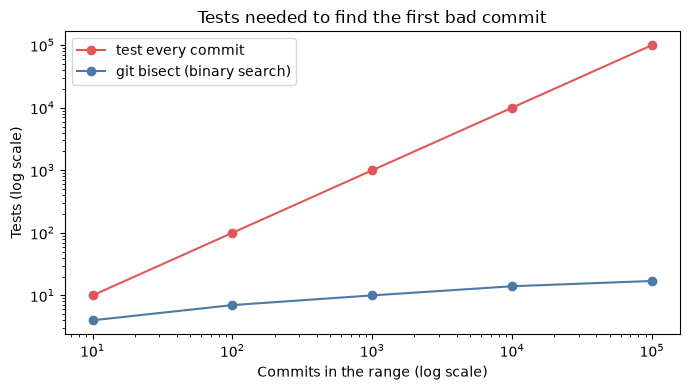

In [8]:
import math
import re

import matplotlib.pyplot as plt

bis = WORK / "bisect-demo"
bis.mkdir()
sh("git init -q -b main", bis)
lines = ["git add -A >/dev/null"]
for i in range(1, 201):
    value = 1 if i < 137 else 0           # commit 137 sets the factor to 0: the bug
    lines.append(f"echo 'FACTOR = {value}  # version {i}' > settings.py && git add settings.py && "
                 f"git commit -q -m 'Change {i}'")
sh(" && ".join(lines[1:]), bis, quiet=True)
(WORK / "test.sh").write_text("#!/bin/bash\ngrep -q 'FACTOR = 1' settings.py\n")   # exit 0 = good, 1 = bad
out = sh(f"git bisect start HEAD HEAD~199 >/dev/null && git bisect run bash {WORK}/test.sh", bis, quiet=True)
first_bad = re.search(r"([0-9a-f]{7,}) is the first bad commit", out).group(1)
steps = out.count("running")
print("first bad commit:", sh(f"git log --format='%h %s' -1 {first_bad}", bis, quiet=True).strip())
print(f"tests run: {steps} (log2(200) = {math.log2(200):.1f})")

ns = [10, 100, 1_000, 10_000, 100_000]
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(ns, ns, marker="o", color="#E15759", label="test every commit")
ax.plot(ns, [math.ceil(math.log2(n)) for n in ns], marker="o", color="#4E79A7", label="git bisect (binary search)")
ax.set(xscale="log", yscale="log", title="Tests needed to find the first bad commit",
       xlabel="Commits in the range (log scale)", ylabel="Tests (log scale)")
ax.legend()
plt.tight_layout()
plt.show()

## 6. Branching Strategies

| Strategy | Idea | Fits |
| :--- | :--- | :--- |
| **GitHub flow** | short-lived feature branches → PR → `main`; `main` is always deployable | most teams, web services |
| **Trunk-based development** | very small changes merged into `main` at least daily; unfinished features hidden behind **feature flags** | teams with strong CI, continuous deployment |
| **Git flow** | long-lived `develop` and `release` branches, hotfix branches | software with scheduled versioned releases |

Two more tools for daily work:

- `git stash` saves unfinished edits so you can switch branches; `git stash pop` brings them back.
- `git cherry-pick <commit>` copies one commit to another branch, for example a hotfix to a release branch.

*Insight: Keep branches short-lived. The longer a branch lives, the more `main` changes under it, and the larger the conflicts at the end. Merge (or rebase) `main` into your branch often, and resolve conflicts while they are small.*

## Real-World Use Case or Analogy

Branches are like **parallel drafts of a document** that several editors prepare at the same time. A fast-forward merge is accepting a draft when nobody else changed the master copy. A conflict is two editors rewriting the same sentence in different ways: a human must decide. Rebase is re-typing your edits on top of the newest master copy, so the final document reads as if you had written them last.

`git bisect` is like finding which of 200 light bulbs in a chain is broken by testing the middle of the chain each time: eight tests instead of up to 200. Teams use `git bisect run` with their test suite to find regressions in large codebases in minutes.